#Example Functions and Definitions

Run once

In [ ]:
# -*- coding: utf-8 -*-
"""
psir_core.py - Shared Core Library for pSIR Metapopulation Models
"""

import csv
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.special import lambertw
from scipy.optimize import root_scalar, minimize


# =============================================================================
# 1. SPATIAL & POPULATION GENERATION
# =============================================================================

def generate_district_positions(D, Lx, Ly, rng):
    """Generates random 2D positions for D districts within [0, Lx] x [0, Ly][cite: 1, 2]."""
    return rng.uniform(0.0, 1.0, size=(D, 2)) * np.array([Lx, Ly])


def generate_district_populations(D, N, c_pop, rng):
    """Generates population sizes for D districts with dispersion parameter c_pop[cite: 1, 2]."""
    if c_pop == 0:
        return np.full(D, N / D)
    raw_pops = rng.uniform(1.0 - c_pop, 1.0 + c_pop, size=D)
    return N * (raw_pops / raw_pops.sum())


def get_connected_components(D, edges):
    """Finds connected components in an undirected graph[cite: 1, 2]."""
    adj = [[] for _ in range(D)]
    for u, v in edges:
        adj[u].append(v)
        adj[v].append(u)

    visited = [False] * D
    components = []

    for i in range(D):
        if not visited[i]:
            comp, queue = [], [i]
            visited[i] = True
            while queue:
                node = queue.pop(0)
                comp.append(node)
                for nb in adj[node]:
                    if not visited[nb]:
                        visited[nb] = True
                        queue.append(nb)
            components.append(comp)
    return components


def generate_fully_connected_backbone(pos, initial_edges=None):
    """Ensures graph connectivity by greedily connecting components via minimal Euclidean distance[cite: 1, 2]."""
    D = len(pos)
    edges = set() if initial_edges is None else {tuple(sorted(e)) for e in initial_edges}
    comps = get_connected_components(D, edges)

    if len(comps) <= 1:
        return edges

    new_edges = set(edges)
    for comp in comps:
        other_nodes = [i for i in range(D) if i not in set(comp)]
        dists = cdist(pos[comp], pos[other_nodes])
        min_i, min_j = np.unravel_index(np.argmin(dists), dists.shape)
        new_edges.add(tuple(sorted((comp[min_i], other_nodes[min_j]))))

    return generate_fully_connected_backbone(pos, initial_edges=new_edges)


def add_random_edge(pos, Nd, edges, alpha=1.0, beta=1.0, gamma=1.0, delta=1.5, rng=None):
    """Adds a single random edge weighted by district populations, degrees, and spatial distance[cite: 1, 2]."""
    if rng is None:
        rng = np.random.default_rng()

    D = len(pos)
    edges = {tuple(sorted(e)) for e in edges}

    if len(edges) >= D * (D - 1) // 2:
        return edges, None

    degrees = np.zeros(D, dtype=int)
    for u, v in edges:
        degrees[u] += 1
        degrees[v] += 1

    w1 = (Nd ** alpha) / ((degrees + 1.0) ** beta)
    p1 = w1 / w1.sum()

    candidates = []
    for _ in range(100):
        u = rng.choice(D, p=p1)
        neighbors = {v for x, v in edges if x == u} | {x for x, v in edges if v == u}
        candidates = [v for v in range(D) if v != u and v not in neighbors]
        if candidates:
            break

    if not candidates:
        return edges, None

    dists = np.linalg.norm(pos[candidates] - pos[u], axis=1)
    w2 = (Nd[candidates] ** gamma) / ((dists + 1e-9) ** delta)
    p2 = w2 / w2.sum()

    v = rng.choice(candidates, p=p2)
    new_edge = tuple(sorted((u, v)))
    edges.add(new_edge)

    return edges, new_edge


# =============================================================================
# 2. MOBILITY & NETWORK TOPOLOGIES
# =============================================================================

def assign_edge_mobilities(edges, p, c_mob, rng=None):
    """Assigns random mobility weights to edges sampled uniformly from [(1-c_mob)*p, (1+c_mob)*p][cite: 1, 2]."""
    if rng is None:
        rng = np.random.default_rng()

    low = (1.0 - c_mob) * p
    high = (1.0 + c_mob) * p

    edge_mobilities = {}
    for u, v in edges:
        w = p if c_mob == 0 else rng.uniform(low, high)
        edge_mobilities[(u, v)] = w
        edge_mobilities[(v, u)] = w
    return edge_mobilities


def build_mobility_matrix(D, edge_mobilities):
    """Constructs row-stochastic mobility matrix P[cite: 1, 2]."""
    P = np.zeros((D, D))
    for (u, v), w in edge_mobilities.items():
        P[u, v] = w

    off_diag_sums = P.sum(axis=1)
    if np.any(off_diag_sums >= 1.0):
        raise ValueError("Total off-diagonal travel exceeds 1.0 for at least one district.")

    np.fill_diagonal(P, 1.0 - off_diag_sums)
    return P


def generate_spatial_network(D, N, c_pop, Lx, Ly, con, p, c_mob,
                             alpha=1.0, beta=1.0, gamma=1.0, delta=1.5, rng_seed=None):
    """Generates a random spatial district network[cite: 1, 2]."""
    rng = np.random.default_rng(rng_seed)
    pos = generate_district_positions(D, Lx, Ly, rng)
    Nd = generate_district_populations(D, N, c_pop, rng)

    edges = generate_fully_connected_backbone(pos)
    target_E = min(int(round((con * D) / 2.0)), D * (D - 1) // 2)
    k_needed = max(0, target_E - len(edges))

    for _ in range(k_needed):
        edges, new_edge = add_random_edge(
            pos, Nd, edges, alpha=alpha, beta=beta, gamma=gamma, delta=delta, rng=rng
        )
        if new_edge is None:
            break

    edge_mobilities = assign_edge_mobilities(edges, p, c_mob, rng)
    P = build_mobility_matrix(D, edge_mobilities)
    return pos, Nd, edges, edge_mobilities, P


def generate_rectangular_network(M1, M2, N, Lx, Ly, p, c_pop=0.0, c_mob=0.0, rng_seed=None):
    """Generates an M1 x M2 2D rectangular grid network[cite: 1]."""
    rng = np.random.default_rng(rng_seed)
    D = M1 * M2

    pos = np.zeros((D, 2))
    dx, dy = Lx / M1, Ly / M2
    for i in range(M1):
        for j in range(M2):
            node = i * M2 + j
            pos[node] = [(i + 0.5) * dx, (j + 0.5) * dy]

    if c_pop == 0:
        Nd = np.full(D, N / D)
    else:
        raw_pops = rng.uniform(1.0 - c_pop, 1.0 + c_pop, size=D)
        Nd = N * (raw_pops / raw_pops.sum())

    edges = set()
    for i in range(M1):
        for j in range(M2):
            u = i * M2 + j
            if i + 1 < M1:
                edges.add(tuple(sorted((u, (i + 1) * M2 + j))))
            if j + 1 < M2:
                edges.add(tuple(sorted((u, i * M2 + (j + 1)))))

    edge_mobilities = assign_edge_mobilities(edges, p, c_mob, rng)
    P = build_mobility_matrix(D, edge_mobilities)
    return pos, Nd, edges, edge_mobilities, P


def get_argentina_network():
    """Returns dataset for the 37 major urban hubs of Argentina with national highway connections[cite: 3]."""
    argentina_37_cities = [
        {"name": "Gran Buenos Aires (AMBA)", "lat": -34.6037, "lon": -58.3816, "pop": 15291277},
        {"name": "Gran Córdoba",            "lat": -31.4201, "lon": -64.1888, "pop": 1705741},
        {"name": "Gran Rosario",            "lat": -32.9468, "lon": -60.6393, "pop": 1455292},
        {"name": "Gran Mendoza",            "lat": -32.8895, "lon": -68.8458, "pop": 1066893},
        {"name": "Gran Tucumán",            "lat": -26.8083, "lon": -65.2176, "pop": 1052194},
        {"name": "Gran La Plata",           "lat": -34.9215, "lon": -57.9545, "pop": 933474},
        {"name": "Gran Salta",              "lat": -24.7859, "lon": -65.4117, "pop": 671015},
        {"name": "Gran San Juan",           "lat": -31.5375, "lon": -68.5364, "pop": 546613},
        {"name": "Neuquén - Plottier",      "lat": -38.9516, "lon": -68.0591, "pop": 551988},
        {"name": "Santiago del Estero",     "lat": -27.7834, "lon": -64.2642, "pop": 449688},
        {"name": "Gran Corrientes",         "lat": -27.4692, "lon": -58.8306, "pop": 427531},
        {"name": "Gran Resistencia",        "lat": -27.4606, "lon": -58.9839, "pop": 407618},
        {"name": "Gran Posadas",            "lat": -27.3671, "lon": -55.8961, "pop": 389070},
        {"name": "Gran Jujuy",              "lat": -24.1858, "lon": -65.2995, "pop": 375794},
        {"name": "Gran Paraná",             "lat": -31.7320, "lon": -60.5289, "pop": 302614},
        {"name": "Gran Formosa",            "lat": -26.1849, "lon": -58.1731, "pop": 260325},
        {"name": "Gran San Luis",           "lat": -33.2950, "lon": -66.3356, "pop": 255454},
        {"name": "Gran Catamarca",          "lat": -28.4696, "lon": -65.7852, "pop": 230366},
        {"name": "Gran La Rioja",           "lat": -29.4131, "lon": -66.8558, "pop": 208638},
        {"name": "Comodoro Rivadavia",      "lat": -45.8647, "lon": -67.4808, "pop": 199369},
        {"name": "Gran Santa Rosa",         "lat": -36.6167, "lon": -64.2833, "pop": 132887},
        {"name": "Bariloche",               "lat": -41.1335, "lon": -71.3103, "pop": 134978},
        {"name": "Río Gallegos",            "lat": -51.6226, "lon": -69.2181, "pop": 115200},
        {"name": "Ushuaia / Río Grande",    "lat": -54.8019, "lon": -68.3030, "pop": 180000},
        {"name": "Mar del Plata",           "lat": -38.0055, "lon": -57.5426, "pop": 644234},
        {"name": "Gran Santa Fe",            "lat": -31.6333, "lon": -60.7000, "pop": 530027},
        {"name": "Gran Bahía Blanca",        "lat": -38.7183, "lon": -62.2663, "pop": 323357},
        {"name": "Gran Río Cuarto",         "lat": -33.1307, "lon": -64.3499, "pop": 189960},
        {"name": "Concordia",               "lat": -31.3930, "lon": -58.0209, "pop": 175683},
        {"name": "San Nicolás",             "lat": -33.3333, "lon": -60.2167, "pop": 160350},
        {"name": "San Rafael",              "lat": -34.6177, "lon": -68.3301, "pop": 139191},
        {"name": "Tandil",                  "lat": -37.3217, "lon": -59.1332, "pop": 138549},
        {"name": "Villa Mercedes",          "lat": -33.6758, "lon": -65.4578, "pop": 132076},
        {"name": "Villa María",             "lat": -32.4075, "lon": -63.2403, "pop": 122321},
        {"name": "Reconquista",             "lat": -29.1500, "lon": -59.6500, "pop": 116426},
        {"name": "Puerto Madryn",            "lat": -42.7692, "lon": -65.0385, "pop": 115000},
        {"name": "Rafaela",                 "lat": -31.2503, "lon": -61.4867, "pop": 103000},
    ]

    D = len(argentina_37_cities)
    Nd = np.array([c["pop"] for c in argentina_37_cities], dtype=float)
    lons = np.array([c["lon"] for c in argentina_37_cities])
    lats = np.array([c["lat"] for c in argentina_37_cities])
    pos = np.column_stack((lons, lats))
    city_idx = {c["name"]: i for i, c in enumerate(argentina_37_cities)}

    highway_connections = [
        ("Gran Buenos Aires (AMBA)", "San Nicolás"),
        ("San Nicolás", "Gran Rosario"),
        ("Gran Rosario", "Villa María"),
        ("Villa María", "Gran Córdoba"),
        ("Gran Córdoba", "Santiago del Estero"),
        ("Santiago del Estero", "Gran Tucumán"),
        ("Gran Tucumán", "Gran Salta"),
        ("Gran Salta", "Gran Jujuy"),
        ("Gran Rosario", "Gran Santa Fe"),
        ("Gran Santa Fe", "Gran Paraná"),
        ("Gran Santa Fe", "Reconquista"),
        ("Reconquista", "Gran Resistencia"),
        ("Gran Resistencia", "Gran Corrientes"),
        ("Gran Corrientes", "Gran Formosa"),
        ("Gran Corrientes", "Gran Posadas"),
        ("Gran Paraná", "Concordia"),
        ("Concordia", "Gran Posadas"),
        ("Gran Santa Fe", "Rafaela"),
        ("Rafaela", "Gran Córdoba"),
        ("Gran Rosario", "Gran Río Cuarto"),
        ("Gran Río Cuarto", "Gran Córdoba"),
        ("Gran Buenos Aires (AMBA)", "Villa Mercedes"),
        ("Villa Mercedes", "Gran San Luis"),
        ("Gran San Luis", "Gran Mendoza"),
        ("Gran Mendoza", "Gran San Juan"),
        ("Gran Río Cuarto", "Villa Mercedes"),
        ("Gran Mendoza", "San Rafael"),
        ("Gran Córdoba", "Gran La Rioja"),
        ("Gran La Rioja", "Gran Catamarca"),
        ("Gran Catamarca", "Gran Tucumán"),
        ("Gran La Rioja", "Gran San Juan"),
        ("Gran Buenos Aires (AMBA)", "Gran La Plata"),
        ("Gran La Plata", "Mar del Plata"),
        ("Gran Buenos Aires (AMBA)", "Tandil"),
        ("Tandil", "Mar del Plata"),
        ("Tandil", "Gran Bahía Blanca"),
        ("Gran Buenos Aires (AMBA)", "Gran Bahía Blanca"),
        ("Gran Río Cuarto", "Gran Santa Rosa"),
        ("Gran Santa Rosa", "Gran Bahía Blanca"),
        ("Gran Bahía Blanca", "Neuquén - Plottier"),
        ("San Rafael", "Neuquén - Plottier"),
        ("Neuquén - Plottier", "Bariloche"),
        ("Gran Bahía Blanca", "Puerto Madryn"),
        ("Puerto Madryn", "Comodoro Rivadavia"),
        ("Bariloche", "Comodoro Rivadavia"),
        ("Comodoro Rivadavia", "Río Gallegos"),
        ("Río Gallegos", "Ushuaia / Río Grande"),
    ]

    edges = {tuple(sorted((city_idx[u], city_idx[v]))) for u, v in highway_connections}
    return pos, Nd, edges, D, argentina_37_cities


# =============================================================================
# 3. GRAPH LAYER ANALYSIS & ODE MODELS
# =============================================================================

def compute_layer_stats(seed_district, edges, Nd, D=None):
    """Computes graph distance layer counts and population totals starting from a seed district[cite: 1, 2, 3]."""
    if D is None:
        D = len(Nd)

    adj = [[] for _ in range(D)]
    for u, v in edges:
        adj[u].append(v)
        adj[v].append(u)

    layer = np.full(D, -1, dtype=int)
    layer[seed_district] = 0
    queue = [seed_district]

    while queue:
        node = queue.pop(0)
        for nb in adj[node]:
            if layer[nb] == -1:
                layer[nb] = layer[node] + 1
                queue.append(nb)

    visited = layer >= 0
    districts_per_layer = np.bincount(layer[visited])
    population_per_layer = np.bincount(layer[visited], weights=Nd[visited])
    return districts_per_layer, population_per_layer


def metapob(x, t, P, beta, gamma, Nd):
    """Full benchmark D-district metapopulation SIR ODE differential equations[cite: 1, 2]."""
    S = x[0::2]
    I = x[1::2]
    Ihat = P.T @ I
    dS = -beta * S / Nd * Ihat
    dI = beta * S / Nd * Ihat - gamma * I
    dx = np.empty_like(x)
    dx[0::2] = dS
    dx[1::2] = dI
    return dx


def solve_Rinf(beta, gamma):
    """Solves transcendental equation Rinf = 1 - exp(-R0 * Rinf)[cite: 1, 2, 3]."""
    def eqRinf(Rinf):
        return Rinf - (1.0 - np.exp(-beta / gamma * Rinf))
    res = root_scalar(eqRinf, x0=0.5, method='newton', bracket=[0, 1])
    return res.root


def compute_psir_parameters(beta, gamma, p, c, pop_counts, rdt=1.0, rtau=1.0, rImax=1.0):
    """Computes theoretical pSIR aggregated model parameters[cite: 1, 2, 5]."""
    Rinf = solve_Rinf(beta, gamma)
    R0 = beta / gamma
    lamb = beta - gamma
    dt = (1.0 / lamb) * lambertw(lamb / (beta * p * c)).real * rdt
    tau = (2.0 * math.log(20) / (beta - gamma)) * rtau
    a = (6.0 - 2.0 * Rinf) / (tau * Rinf)
    b = Rinf / (3.0 - Rinf)
    Imax = pop_counts[0] * (1.0 - 1.0 / R0 - (1.0 / R0) * math.log(R0)) * rImax
    return Rinf, R0, dt, tau, a, b, Imax


def Pinterp(pS, pop_values):
    """Linearly interpolates population layer capacity given accumulated population pS[cite: 1, 2, 3]."""
    cum_sum = np.cumsum(pop_values)
    cum_prev = np.insert(cum_sum[:-1], 0, 0.0)
    midpoints = (cum_prev + cum_sum) / 2.0
    x_nodes = np.insert(midpoints, 0, 0.0)
    y_nodes = np.insert(pop_values, 0, 0.0)
    return np.interp(pS, x_nodes, y_nodes)

def Pclosed2(pS,rmax,Lmax,phi,N,D):
    u = np.maximum(0.0, N - pS)
    pS_safe = np.maximum(0.0, pS)
    term2 = np.sqrt(2.0 * N/D * u)
    term3 = N/D * Lmax
    term4 = np.sqrt(2.0 * N/D * pS_safe)
    return np.minimum.reduce([term2, term3, term4])

def pSIR_model2(x, t, N, pop_values, dt, beta, gamma, Imax, a, b, Rinf,rmax=2,Lmax=2,phi=0,D=10,mode='interp'):
    """Aggregated macro pSIR differential equation system[cite: 1, 2, 3, 5]."""
    pS, pR, S, I, R = x
    pI = N - pS - pR
    if pI < N / 1e10:
        pI = N / 1e10
    if mode=='interp':
      dpS = -Pinterp(N - pS, pop_values) / dt * min(1.0, (I / Imax) ** 2)
    else:
      dpS = -Pclosed2(N - pS, rmax, Lmax,phi,N,D) / dt * min(1.0, (I / Imax) ** 2)
    dpR = a * (R - b * S - b * I)
    if dpR < 0:
        dpR = 0.0
    dS = -dpS - beta * I * S / pI - (1.0 - Rinf) * dpR
    dI = beta * I * S / pI - gamma * I
    dR = gamma * I - Rinf * dpR
    return [dpS, dpR, dS, dI, dR]


# =============================================================================
# 4. DATA LOADERS & VISUALIZATION UTILITIES
# =============================================================================

def read_single_row_csv_as_ints(filename):
    """Reads single-row CSV as integer list[cite: 3]."""
    with open(filename, 'r', newline='') as file:
        reader = csv.reader(file)
        try:
            return [int(val) for val in next(reader)]
        except (StopIteration, ValueError):
            return []


def read_single_column_csv_as_ints(filename):
    """Reads single-column CSV as integer list[cite: 3]."""
    data = []
    with open(filename, 'r') as file:
        for row in csv.reader(file):
            if row:
                data.append(int(row[0]))
    return data


def moving_average(data, window_size):
    """Calculates windowed moving average[cite: 3]."""
    weights = np.ones(window_size) / window_size
    return np.convolve(data, weights, mode='valid')


def plot_spatial_network(pos, Nd, edges, edge_mobilities, Lx, Ly, p, title="Spatial Network"):
    """Plots spatial network topology with edges weighted by mobility[cite: 1, 2]."""
    D = len(pos)
    N = Nd.sum()
    plt.figure(figsize=(9.5, 4.5))

    for u, v in edges:
        w = edge_mobilities[(u, v)]
        lw = 2.5 * (w / p)
        plt.plot([pos[u, 0], pos[v, 0]], [pos[u, 1], pos[v, 1]], color='slategray', lw=lw, alpha=0.6)

    base_area = 180
    circle_areas = base_area * (Nd / (N / D))
    plt.scatter(pos[:, 0], pos[:, 1], s=circle_areas, color='skyblue', edgecolor='navy', alpha=0.85, zorder=3)

    for i, (x, y) in enumerate(pos):
        plt.annotate(str(i), (x, y), ha='center', va='center', fontsize=7, fontweight='bold', zorder=4)

    plt.xlim(0, Lx)
    plt.ylim(0, Ly)
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    plt.title(title)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.grid(True, linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.savefig(f'{title}.pdf', bbox_inches='tight')
    plt.show()


def plot_argentina_network(pos, Nd, edges, cities_data):
    """Plots Argentina 37 major urban hub spatial graph[cite: 3]."""
    plt.figure(figsize=(9, 13))

    for u, v in edges:
        plt.plot([pos[u, 0], pos[v, 0]], [pos[u, 1], pos[v, 1]], color='slategray', lw=1.3, alpha=0.6)

    circle_areas = 120 * (Nd / Nd.mean())
    plt.scatter(pos[:, 0], pos[:, 1], s=circle_areas, color='skyblue', edgecolor='navy', alpha=0.85, zorder=3)

    for i, c in enumerate(cities_data):
        weight = 'bold' if c["pop"] > 1000000 else 'normal'
        size = 7.5 if c["pop"] > 1000000 else 6.5
        plt.annotate(c["name"], (pos[i, 0], pos[i, 1]), xytext=(5, 2), textcoords="offset points",
                     fontsize=size, fontweight=weight, zorder=4)

    plt.xlabel("Longitude (°W)")
    plt.ylabel("Latitude (°S)")
    plt.title("Argentina Spatial Network (37 Urban Hubs)")
    plt.gca().set_aspect('equal', adjustable='box')
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'Argentina_network.pdf', bbox_inches='tight')
    plt.show()


In [ ]:
# -*- coding: utf-8 -*-
"""
Examples.py - Execution Driver Script for pSIR Article Examples
"""
from scipy.integrate import odeint
from scipy.optimize import minimize



# =============================================================================
# EXAMPLE 1: RANDOM SPATIAL NETWORK (psir_random.py)
# =============================================================================
def run_example_random_network(D = 40, seed = 1, N = 1e6, c_pop = 0.75, Lx = 2.5, Ly = 1.0, con = 2.5, p = 0.005, c_mob = 0.75, seed_district = 0, beta = 1.0
,gamma = 0.5, I0 = 1.0, t_end = 200,
                               plot_network=True, plot_results=True, verbose=True):
    """Runs the metapopulation benchmark and the aggregated pSIR model on a random spatial network.
    plot_network / plot_results switch the internal plots on or off, verbose the layer table.
    Returns: t_eval, I_districts (time x D), Itot, I_psir."""
    # 1. Generate Network
    pos, Nd, edges, edge_mobilities, P = generate_spatial_network(
        D=D, N=N, c_pop=c_pop, Lx=Lx, Ly=Ly, con=con, p=p, c_mob=c_mob, rng_seed=seed
    )
    if plot_network:
        plot_spatial_network(pos, Nd, edges, edge_mobilities, Lx, Ly, p, title=f"Random Spatial Network (D={D})")

    # 2. Benchmark Metapopulation ODE Simulation

    x0 = np.zeros(D * 2)
    x0[0::2] = Nd
    x0[seed_district * 2] = Nd[seed_district] - I0
    x0[seed_district * 2 + 1] = I0

    t_eval = np.linspace(0, t_end, 20 * t_end)
    sol_meta = odeint(metapob, x0, t_eval, args=(P, beta, gamma, Nd), rtol=1e-6)
    Itot = sol_meta[:, 1::2].sum(axis=1)

    # 3. Aggregated pSIR Model Simulation
    dist_counts, pop_counts = compute_layer_stats(seed_district, edges, Nd)
    pop_counts = np.append(pop_counts, 0.0)
    if verbose:
        for k, (count, pop) in enumerate(zip(dist_counts, pop_counts)):
            print(f"Layer {k}: {count:2d} districts | Population: {pop:,.1f}")

    Rinf, R0, dt, tau, a, b, Imax = compute_psir_parameters(
        beta=beta, gamma=gamma, p=p, c=con, pop_counts=pop_counts
    )

    pI_0 = pop_counts[0]
    pS_0 = N - pI_0
    S_0 = pI_0 - I0
    R_0, pR_0 = 0.0, 0.0
    x0_psir = [pS_0, pR_0, S_0, I0, R_0]

    sol_psir = odeint(
        pSIR_model2, x0_psir, t_eval,
        args=(N, pop_counts, dt, beta, gamma, Imax, a, b, Rinf),
        rtol=1e-6, atol=1e-9
    )

    # 4. Compare Models
    if plot_results:
        plt.figure(figsize=(10, 6))
        plt.plot(t_eval, sol_psir[:, 3], label='pSIR Aggregated Model (I)', lw=2.5)
        plt.plot(t_eval, Itot, label='Benchmark Network Model (Itot)', lw=2.0, ls='--')
        plt.title(f'Aggregated pSIR Model vs Random Network ($D={D}$)')
        plt.xlabel('Time (days)')
        plt.ylabel('Infected individuals')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.legend()
        plt.tight_layout()
        plt.savefig(f'random_network_result(D={D}).pdf', bbox_inches='tight'
        )

        plt.show()

    return t_eval, sol_meta[:, 1::2], Itot, sol_psir[:, 3]


# =============================================================================
# EXAMPLE 2: RECTANGULAR GRID NETWORK (psir_rectangle.py)
# =============================================================================
def run_example_rectangular_grid(seed = 1, M1 = 10, M2 = 2, N = 1e6, p = 0.005, seed_district = 0, beta = 1.0
,gamma = 0.5, I0 = 10.0, t_end = 200, mode='interp',
                                 plot_network=True, plot_results=True):
    """Runs the metapopulation benchmark and the aggregated pSIR model on an M1 x M2 grid.
    plot_network / plot_results switch the internal plots on or off.
    Returns: t_eval, I_districts (time x D), Itot, I_psir."""
    Lx, Ly = M1/M2, 1
    D = M1 * M2
    c_pop = 0.0
    c_mob = 0.0
    # 1. Generate Rectangular Network
    pos, Nd, edges, edge_mobilities, P = generate_rectangular_network(
        M1=M1, M2=M2, N=N, Lx=Lx, Ly=Ly, p=p, c_pop=c_pop, c_mob=c_mob, rng_seed=seed
    )
    con = 2.0 * len(edges) / D
    if plot_network:
        plot_spatial_network(pos, Nd, edges, edge_mobilities, Lx, Ly, p, title=f"Rectangular Grid ($M_1={M1}, M_2={M2}$)")

    x0 = np.zeros(D * 2)
    x0[0::2] = Nd
    x0[seed_district * 2] = Nd[seed_district] - I0
    x0[seed_district * 2 + 1] = I0

    t_eval = np.linspace(0, t_end, 20 * t_end)
    sol_meta = odeint(metapob, x0, t_eval, args=(P, beta, gamma, Nd), rtol=1e-6)
    Itot = sol_meta[:, 1::2].sum(axis=1)

    # 3. Aggregated pSIR Model
    dist_counts, pop_counts = compute_layer_stats(seed_district, edges, Nd)
    pop_counts = np.append(pop_counts, 0.0)

    Rinf, R0, dt, tau, a, b, Imax = compute_psir_parameters(
        beta=beta, gamma=gamma, p=p, c=con, pop_counts=pop_counts
    )

    pI_0 = pop_counts[0]
    pS_0 = N - pI_0
    S_0 = pI_0 - I0
    R_0, pR_0 = 0.0, 0.0
    x0_psir = [pS_0, pR_0, S_0, I0, R_0]
    rmax = M1 + 1
    Lmax = M2
    phi = 0

    sol_psir = odeint(
        pSIR_model2, x0_psir, t_eval,
        args=(N, pop_counts, dt, beta, gamma, Imax, a, b, Rinf, rmax, Lmax, phi, D, mode),
        rtol=1e-6, atol=1e-9
    )

    # 4. Plot Comparison
    if plot_results:
        plt.figure(figsize=(10, 6))
        plt.plot(t_eval, sol_psir[:, 3], label='pSIR Aggregated Model (I)', lw=2.5)
        plt.plot(t_eval, Itot, label='Grid Network Model (Itot)', lw=2.0, ls='--')
        plt.title(f'Aggregated Model vs Rectangular Grid Network ($M_1={M1}, M_2={M2}$)')
        plt.xlabel('Time (days)')
        plt.ylabel('Infected individuals')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.legend()
        plt.tight_layout()
        plt.savefig('rectangular_grid.pdf', bbox_inches='tight')

        plt.show()

    return t_eval, sol_meta[:, 1::2], Itot, sol_psir[:, 3]


# =============================================================================
# EXAMPLE 3: ARGENTINA REAL DATA & FITTING (psirargentina.py)
# =============================================================================
def run_example_argentina_fitting(dt0 = 8.0, beta0 = 0.2, gamma = 0.16,  N = 45e6, scale = 1.0 / 11.0):
    pos, Nd, edges, D, cities = get_argentina_network()
    plot_argentina_network(pos, Nd, edges, cities)

    # Layer Statistics starting from AMBA (seed_district = 0)
    seed_district = 0
    # Epidemiological Setup
    beta = beta0
    dt = dt0

    dist_counts, pop_counts = compute_layer_stats(seed_district, edges, Nd)
    fact= (N-pop_counts[0])/(pop_counts.sum()-pop_counts[0])
    # Apply 1.3 scaling factor for non-seed layers[cite: 3]
    for k in range(1, len(pop_counts)):
        pop_counts[k] *= fact
    pop_counts = np.append(pop_counts, 0.0)
    print("Total population after correction=",pop_counts.sum())

    for k, (count, pop) in enumerate(zip(dist_counts, pop_counts)):
      print(f"Layer {k}: {count:2d} districts | Corrected Population: {pop:,.1f}")


    # Load real COVID-19 data if available; fallback to synthetic data if missing
    try:
        !wget -O nacion.csv https://fceia.unr.edu.ar/~kofman/files/nacion.csv
        data_read = read_single_column_csv_as_ints('nacion.csv')
        data = [x / 1.0 for x in data_read[100:340]]
        filt_data = moving_average(data, 7)
    except Exception:
        print("Dataset 'nacion.csv' not found. Generating dummy time series for demonstration.")
        filt_data = np.sin(np.linspace(0, np.pi, 233)) * 15000 + 500

    T = len(filt_data)
    time_points = np.linspace(0, T - 1, T)

    pI_0 = pop_counts[0]
    pS_0 = N - pI_0

    # Parameter fitting function
    def get_simulated_cases(t_eval, rdt, rbeta):
        effective_beta = beta * rbeta
        Rinf = solve_Rinf(effective_beta, gamma)
        R0 = effective_beta / gamma
        tau = 2.0 * math.log(20) / (effective_beta - gamma)
        a = (6.0 - 2.0 * Rinf) / (tau * Rinf)
        b = Rinf / (3.0 - Rinf)

        Imax = pop_counts[0] * (1.0 - 1.0 / R0 - (1.0 / R0) * math.log(R0))
        I_0 = filt_data[1] / beta / scale
        S_0 = pI_0 - I_0
        R_0, pR_0 = 0.0, 0.0
        x0 = [pS_0, pR_0, S_0, I_0, R_0]

        sol = odeint(
            pSIR_model2, x0, t_eval,
            args=(N, pop_counts, dt * rdt, effective_beta, gamma, Imax, a, b, Rinf),
            rtol=1e-6, atol=1e-9
        )
        S, I, R = sol[:, 2], sol[:, 3], sol[:, 4]
        C = effective_beta * I * S / (S + I + R)
        return C * scale

    def loss_function(params):
        rdt, rbeta = params
        if rdt <= 0 or rbeta <= 0:
            return 1e12
        try:
            I_sim = get_simulated_cases(time_points, rdt, rbeta)
            return np.sum((filt_data - I_sim) ** 2)
        except Exception:
            return 1e12

    # Initial plot
    I_Initial = get_simulated_cases(time_points, 1, 1)
    plt.figure(figsize=(10, 6))
    plt.plot(time_points, I_Initial, label='Initial Aggregated Model', lw=2.0)
    plt.plot(time_points, filt_data, label='Reported Daily Cases', lw=1.5, ls='--')
    plt.title('pSIR Aggregated Model vs Argentina Real Data')
    plt.xlabel('Time (days)')
    plt.ylabel('Daily Cases')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.savefig('Argentina_initial.pdf', bbox_inches='tight')
    plt.show()

    # Fit parameters using Nelder-Mead
    initial_guess = [1.0, 1.0]
    par_bounds = [(0.1, 10.0), (gamma / beta, 2.0 * gamma / beta)]
    res = minimize(loss_function, initial_guess, method='Nelder-Mead', bounds=par_bounds, options={'maxiter': 100})
    rdt_opt, rbeta_opt = res.x

    print(f"Optimal dt  = {dt * rdt_opt:.2f} days")
    print(f"Optimal beta = {beta * rbeta_opt:.4f}")

    # Final plot
    I_fitted = get_simulated_cases(time_points, rdt_opt, rbeta_opt)
    plt.figure(figsize=(10, 6))
    plt.plot(time_points, I_fitted, label='Fitted Aggregated Model', lw=2.0)
    plt.plot(time_points, filt_data, label='Reported Daily Cases', lw=1.5, ls='--')
    plt.title('pSIR Aggregated Model vs Argentina Real Data')
    plt.xlabel('Time (days)')
    plt.ylabel('Daily Cases')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.savefig('Argentina_fitted.pdf', bbox_inches='tight')
    plt.show()




# Rectangular Grid

Default Parameters:
seed = 1, M1 = 10, M2 = 2, N = 1e6, p = 0.005, seed_district = 0, beta = 1.0
,gamma = 0.5, I0 = 10.0, t_end = 200, mode = 'interp', plot_network=True, plot_results=True)

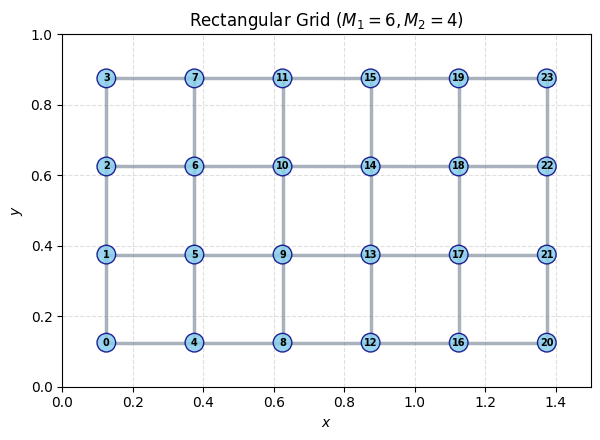

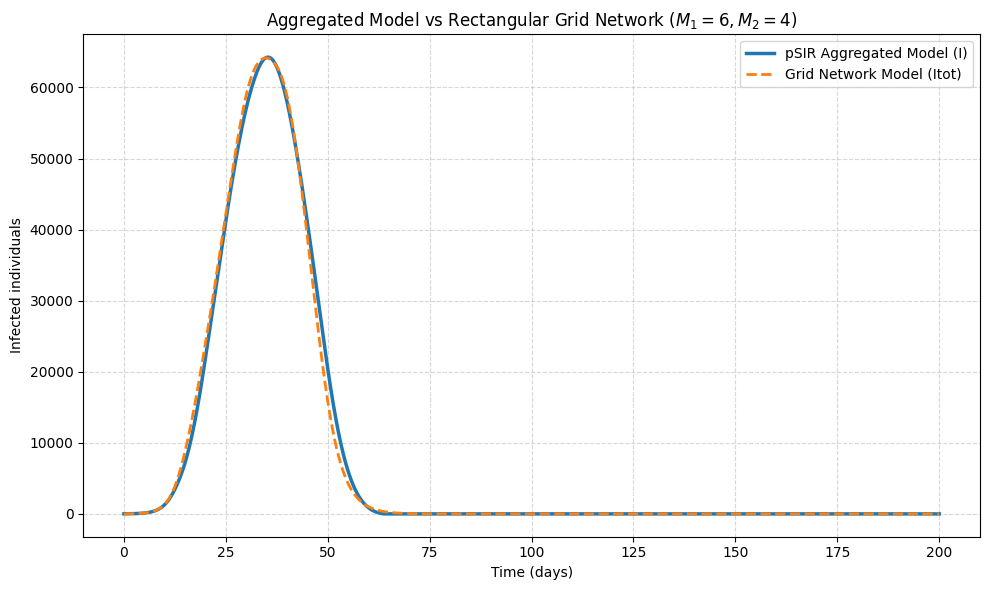

(array([0.00000000e+00, 5.00125031e-02, 1.00025006e-01, ...,
        1.99899975e+02, 1.99949987e+02, 2.00000000e+02]),
 array([[ 1.00000000e+01,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 1.02428437e+01,  5.12145077e-03,  1.28055700e-06, ...,
          2.16486561e-21,  6.12673322e-25,  9.94949301e-29],
        [ 1.04915837e+01,  1.04890825e-02,  5.24489791e-06, ...,
          9.59077845e-20,  4.62882590e-23,  1.35401170e-26],
        ...,
        [-2.48985118e-14, -6.88677717e-14, -2.10468675e-13, ...,
         -1.29427079e-11, -2.80301061e-11, -5.35386021e-11],
        [-2.48829250e-14, -6.88246498e-14, -2.10336849e-13, ...,
         -1.29345973e-11, -2.80125391e-11, -5.35050405e-11],
        [-2.48673382e-14, -6.87815279e-14, -2.10205023e-13, ...,
         -1.29264867e-11, -2.79949721e-11, -5.34714789e-11]]),
 array([ 1.00000000e+01,  1.02530917e+01,  1.05125829e+01, ...,
        -1.69417321e-10, -1.69311150e-10, -1.6

In [ ]:
run_example_rectangular_grid(M1=6,M2=4,p=0.01,mode='closed')


# Random Network
Default Parameters: D = 40, seed = 1, N = 1e6, c_pop = 0.75, Lx = 2.5, Ly = 1.0, con = 2.5, p = 0.005, c_mob = 0.75, seed_district = 0, beta = 1.0
,gamma = 0.5, I0 = 1.0, t_end = 200

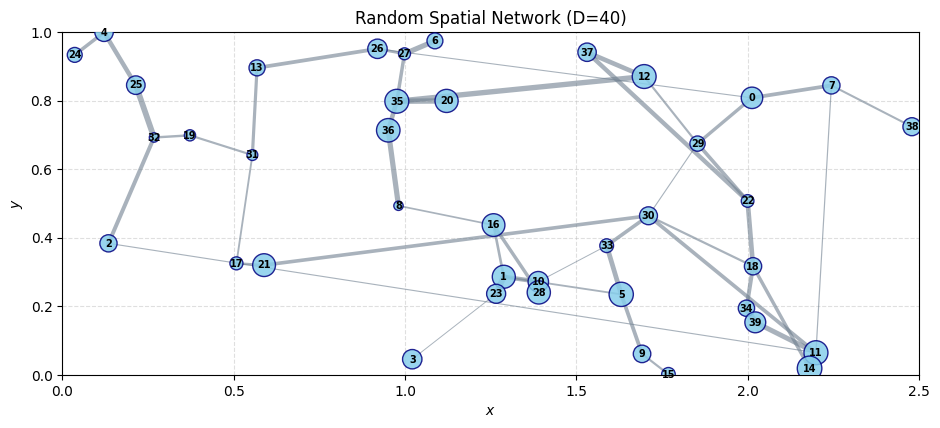

Layer 0:  1 districts | Population: 33,086.7
Layer 1:  3 districts | Population: 65,228.1
Layer 2:  7 districts | Population: 169,300.6
Layer 3: 10 districts | Population: 260,912.7
Layer 4:  8 districts | Population: 197,349.0
Layer 5:  5 districts | Population: 130,089.1
Layer 6:  4 districts | Population: 100,972.2
Layer 7:  2 districts | Population: 43,061.6


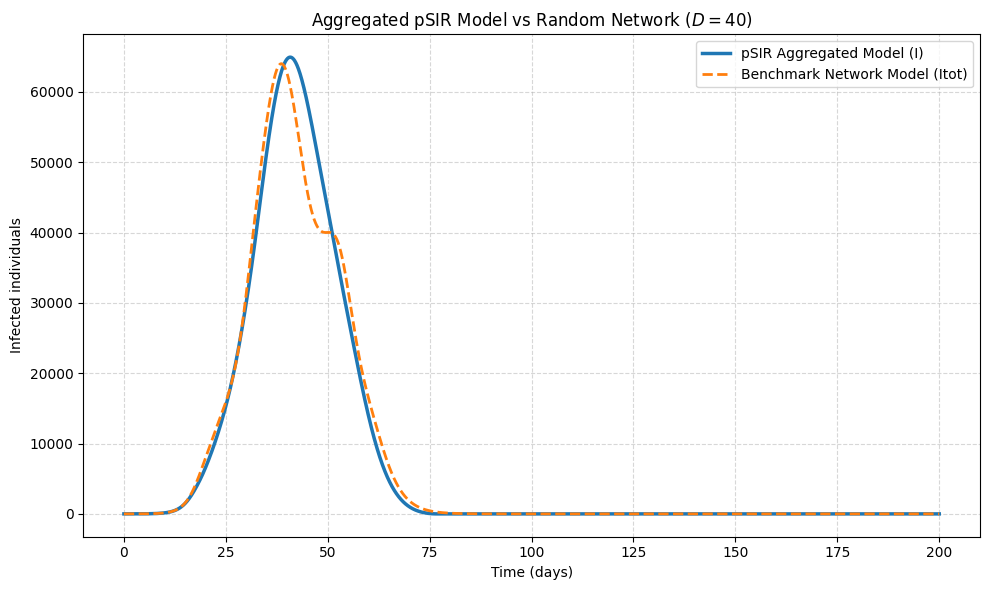

(array([0.00000000e+00, 5.00125031e-02, 1.00025006e-01, ...,
        1.99899975e+02, 1.99949987e+02, 2.00000000e+02]),
 array([[ 1.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 1.02471567e+00,  4.23977413e-21,  3.73807229e-13, ...,
          6.35231406e-12,  2.06740019e-08,  1.63870967e-12],
        [ 1.05004194e+00,  1.33409020e-19,  2.74162370e-12, ...,
          4.65836845e-11,  8.45511930e-08,  1.20176799e-11],
        ...,
        [-6.71701476e-16, -2.63915809e-12, -6.07637114e-14, ...,
         -1.16709004e-14, -4.13985926e-15, -3.84703647e-14],
        [-6.71406558e-16, -2.63799883e-12, -6.07370212e-14, ...,
         -1.16657728e-14, -4.13804037e-15, -3.84534626e-14],
        [-6.71111640e-16, -2.63683958e-12, -6.07103310e-14, ...,
         -1.16606452e-14, -4.13622148e-15, -3.84365604e-14]]),
 array([ 1.00000000e+00,  1.02532032e+00,  1.05128134e+00, ...,
        -8.10289746e-11, -8.09933745e-11, -8.0

In [ ]:
run_example_random_network(seed=5,D=40)


# Fitting Real Data from Argentina
Default parameters: dt0 = 8.0, beta0 = 0.2, gamma = 0.16,  N = 45e6, scale = 1/11

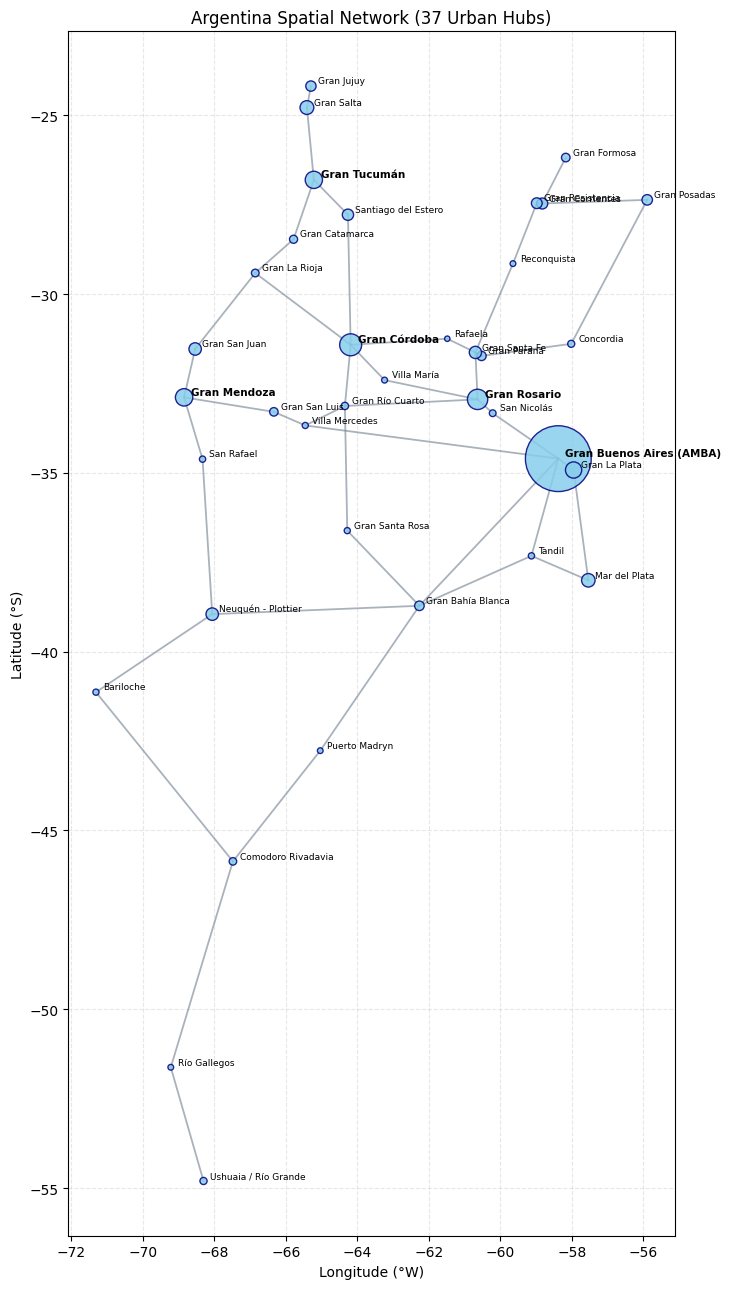

Total population after correction= 45000000.0
Layer 0:  1 districts | Corrected Population: 15,291,277.0
Layer 1:  5 districts | Corrected Population: 3,355,607.5
Layer 2:  7 districts | Corrected Population: 6,649,986.0
Layer 3:  7 districts | Corrected Population: 7,750,833.3
Layer 4:  7 districts | Corrected Population: 3,662,523.8
Layer 5:  5 districts | Corrected Population: 4,067,473.7
Layer 6:  3 districts | Corrected Population: 2,957,600.2
Layer 7:  2 districts | Corrected Population: 1,264,698.5
--2026-10-13 17:02:06--  https://fceia.unr.edu.ar/~kofman/files/nacion.csv
Resolving fceia.unr.edu.ar (fceia.unr.edu.ar)... 200.3.123.187
Connecting to fceia.unr.edu.ar (fceia.unr.edu.ar)|200.3.123.187|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4421 (4.3K) [text/csv]
Saving to: ‘nacion.csv’

nacion.csv          100%[===================>]   4.32K  --.-KB/s    in 0s      

2026-10-13 17:02:07 (1.40 GB/s) - ‘nacion.csv’ saved [4421/4421]



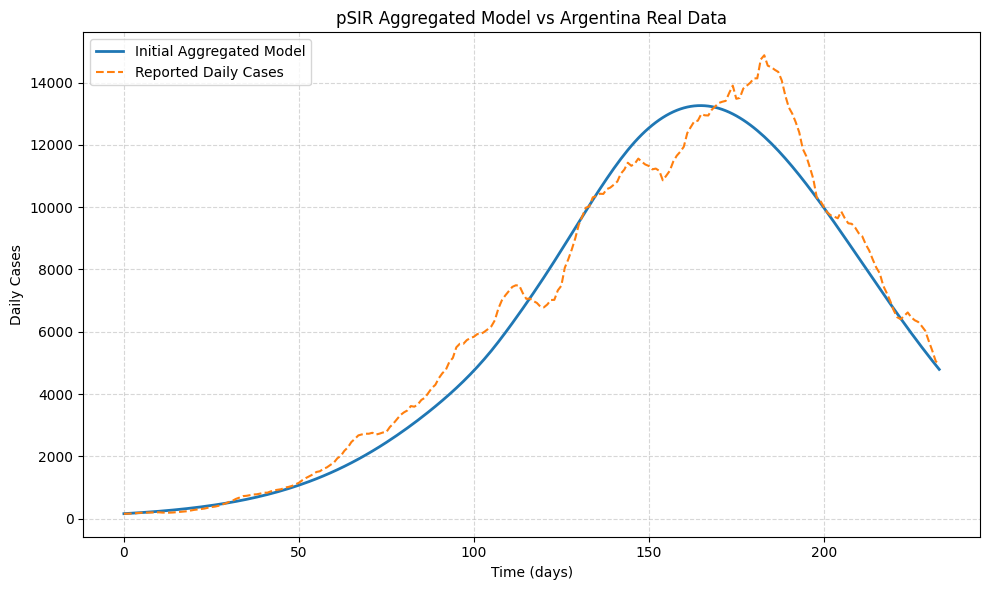

Optimal dt  = 12.25 days
Optimal beta = 0.2021


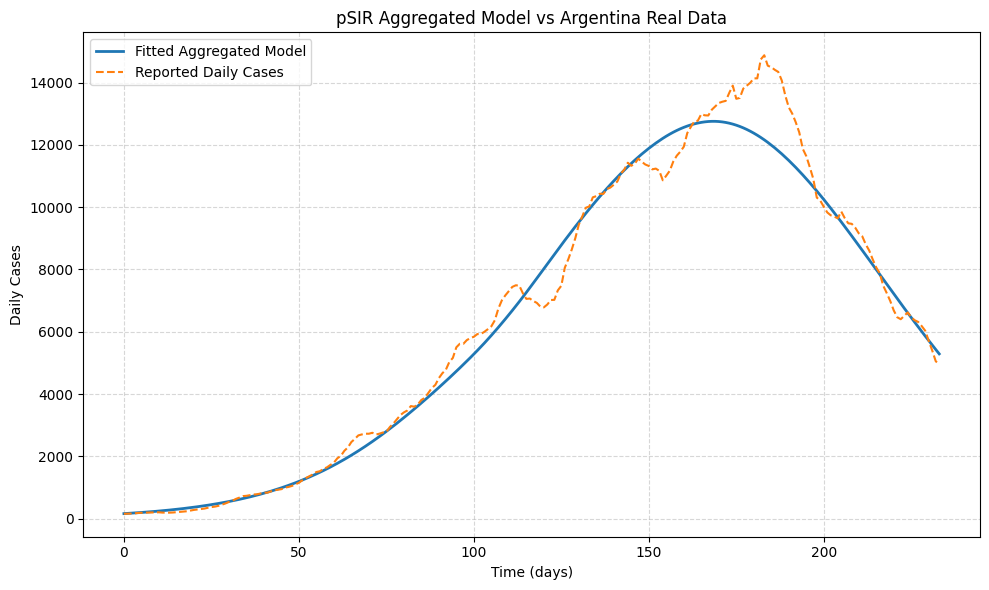

In [ ]:
run_example_argentina_fitting()

#Example 1: Rectangular Grid

- Metapop and pSIR: base case
- Variations

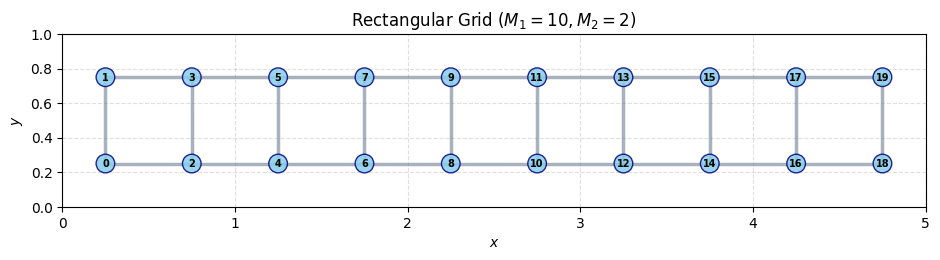

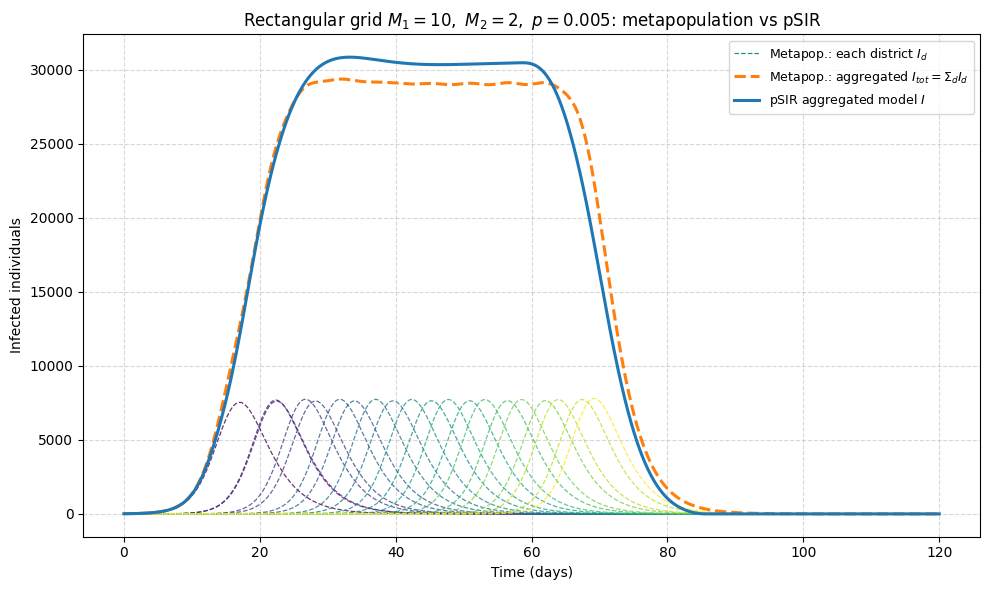

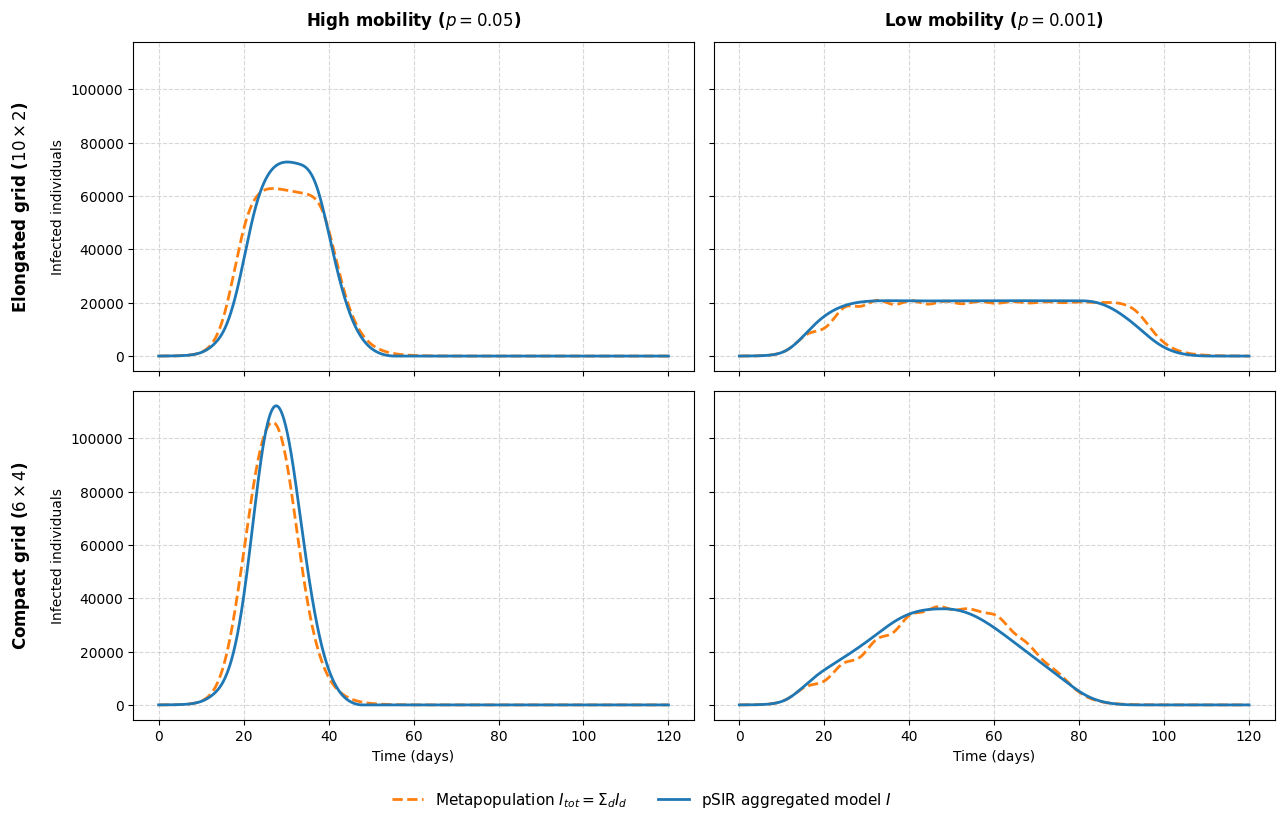

In [ ]:
# =============================================================================
# EXAMPLE 1.a - Base case: M1=10, M2=2, p=0.005 (default parameters), mode='closed'
# =============================================================================
M1, M2, seed_district = 10, 2, 0
t, I_districts, Itot, I_psir = run_example_rectangular_grid(
    M1=M1, M2=M2, t_end=120, p=0.005, mode='closed', plot_network=True, plot_results=False
)

# Layer of each district = graph distance to the seed (Manhattan distance on the grid)
i0, j0 = divmod(seed_district, M2)
layer_of = np.array([abs(d // M2 - i0) + abs(d % M2 - j0) for d in range(M1 * M2)])
cmap, norm = plt.cm.viridis, plt.Normalize(0, layer_of.max())

fig, ax = plt.subplots(figsize=(10, 6))
for d in range(M1 * M2):
    ax.plot(t, I_districts[:, d], ls='--', lw=0.9, alpha=0.8, color=cmap(norm(layer_of[d])))
ax.plot([], [], ls='--', lw=0.9, color=cmap(0.5), label='Metapop.: each district $I_d$')
ax.plot(t, Itot, ls='--', lw=2.2, color='tab:orange', label=r'Metapop.: aggregated $I_{tot}=\Sigma_d I_d$')
ax.plot(t, I_psir, ls='-', lw=2.2, color='tab:blue', label='pSIR aggregated model $I$')

#fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=ax,
 #            label='Layer (graph distance to seed district)')
ax.set_title(rf'Rectangular grid $M_1={M1},\ M_2={M2},\ p=0.005$: metapopulation vs pSIR')
ax.set_xlabel('Time (days)')
ax.set_ylabel('Infected individuals')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('example1_base_case.pdf', bbox_inches='tight')
plt.show()



# =============================================================================
# EXAMPLE 1.b - Parameter variations: mobility p and district shape (M1, M2)
# Rows: district shape. Columns: mobility.
# Same style as the base case: orange dashed = metapopulation, blue solid = pSIR.
# =============================================================================
shapes = [(10, 2), (6, 4)]        # elongated grid, compact grid
mobilities = [0.05, 0.001]        # high mobility, low mobility

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True, sharey=True)
for r, (M1, M2) in enumerate(shapes):
    for c, p in enumerate(mobilities):
        ax = axes[r, c]
        t, I_districts, Itot, I_psir = run_example_rectangular_grid(
            M1=M1, M2=M2, p=p, mode='closed', t_end=120,
            plot_network=False, plot_results=False
        )
        ax.plot(t, Itot, ls='--', lw=2.0, color='tab:orange', label=r'Metapopulation $I_{tot}=\Sigma_d I_d$')
        ax.plot(t, I_psir, ls='-', lw=2.0, color='tab:blue', label='pSIR aggregated model $I$')
        ax.grid(True, linestyle='--', alpha=0.5)
        if r == 1:
            ax.set_xlabel('Time (days)')
        if c == 0:
            ax.set_ylabel('Infected individuals')

# Column / row headers
for c, txt in enumerate(['High mobility ($p=0.05$)', 'Low mobility ($p=0.001$)']):
    axes[0, c].annotate(txt, xy=(0.5, 1.05), xycoords='axes fraction',
                        ha='center', fontsize=12, fontweight='bold')
for r, txt in enumerate(['Elongated grid ($10\\times2$)', 'Compact grid ($6\\times4$)']):
    axes[r, 0].annotate(txt, xy=(-0.2, 0.5), xycoords='axes fraction',
                        ha='center', va='center', rotation=90, fontsize=12, fontweight='bold')

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=11, frameon=False)
plt.tight_layout(rect=[0.02, 0.05, 1, 0.97])
plt.savefig('example1_variations.pdf', bbox_inches='tight')
plt.show()


#Example 2: Random population

- Metapop and pSIR: base case
- Variations


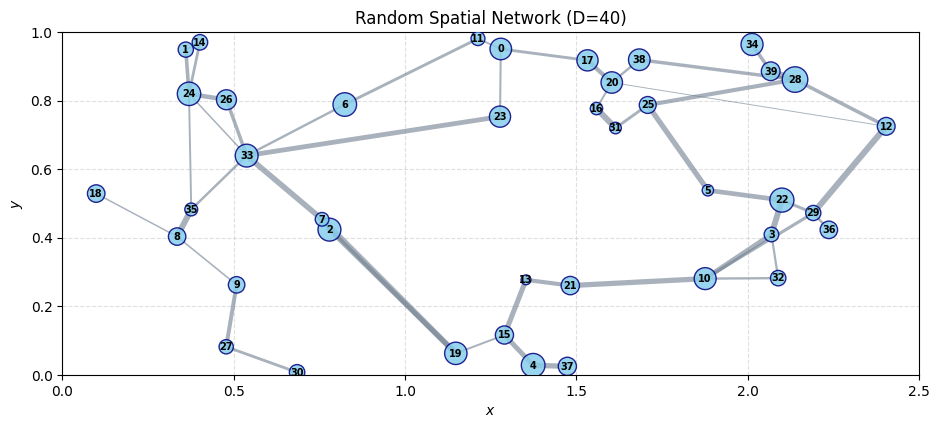

Layer 0:  1 districts | Population: 33,427.6
Layer 1:  3 districts | Population: 78,569.7
Layer 2:  3 districts | Population: 110,849.1
Layer 3:  7 districts | Population: 160,907.1
Layer 4:  8 districts | Population: 203,021.3
Layer 5:  8 districts | Population: 209,545.7
Layer 6:  8 districts | Population: 162,810.6
Layer 7:  2 districts | Population: 40,868.8


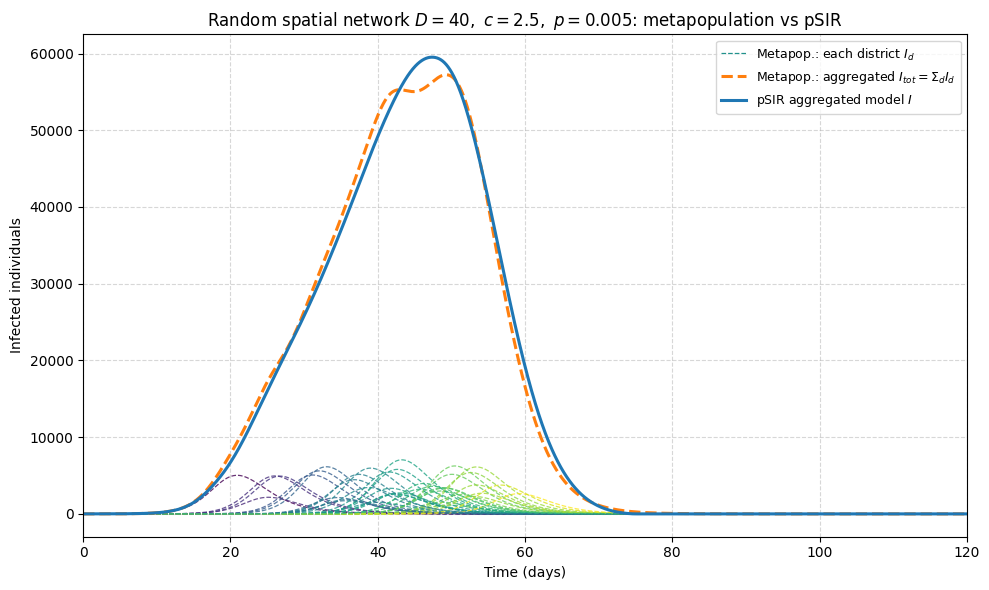

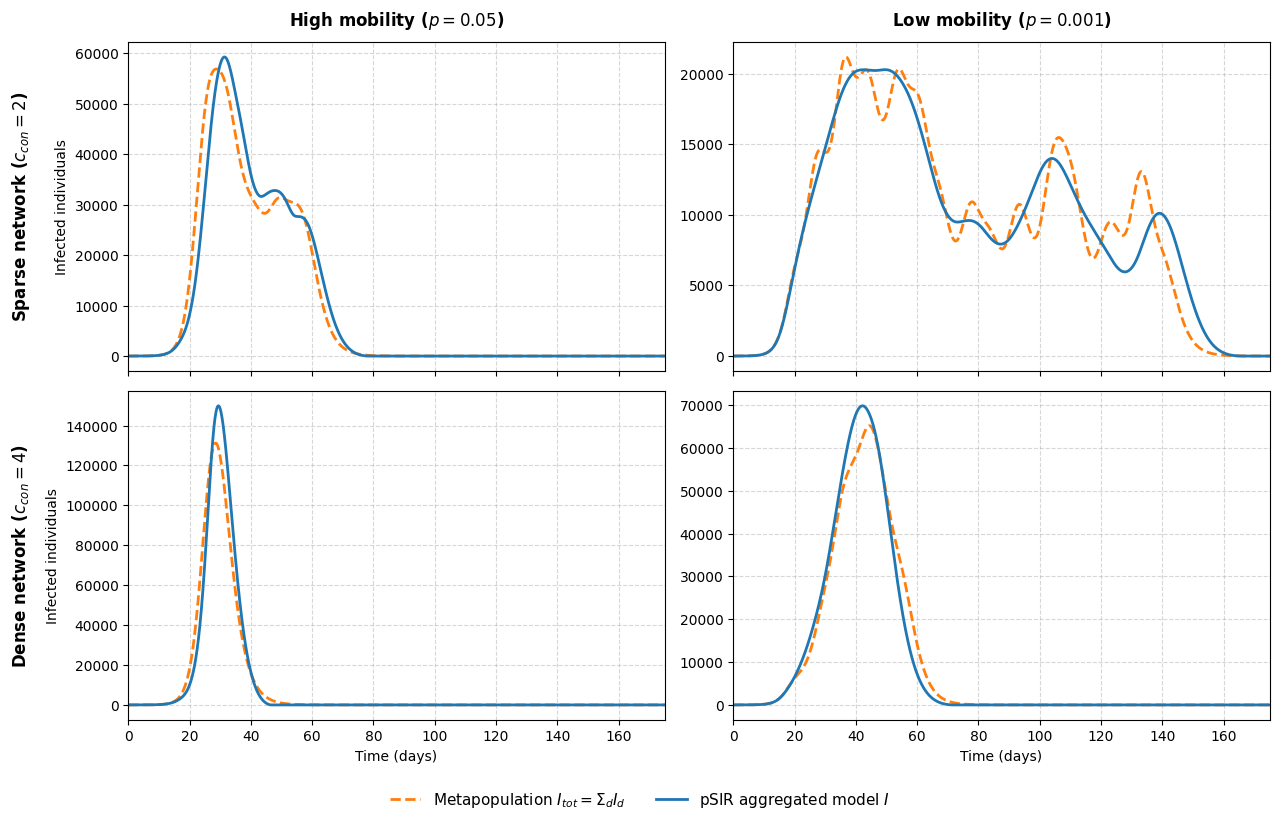

In [ ]:
#  =============================================================================
# EXAMPLE 2.a - Base case: random spatial network with default parameters
# D=40, seed=1, N=1e6, c_pop=0.75, Lx=2.5, Ly=1, con=2.5, p=0.005, c_mob=0.75, I0=1
# =============================================================================
t, I_districts, Itot, I_psir = run_example_random_network(
    plot_network=True, plot_results=False, verbose=True
)

# Color each district by the time of its own peak (a proxy for its distance to the seed)
D = I_districts.shape[1]
t_peak = t[I_districts.argmax(axis=0)]
cmap, norm = plt.cm.viridis, plt.Normalize(t_peak.min(), t_peak.max())

fig, ax = plt.subplots(figsize=(10, 6))
for d in range(D):
    ax.plot(t, I_districts[:, d], ls='--', lw=0.9, alpha=0.8, color=cmap(norm(t_peak[d])))
ax.plot([], [], ls='--', lw=0.9, color=cmap(0.5), label='Metapop.: each district $I_d$')
ax.plot(t, Itot, ls='--', lw=2.2, color='tab:orange', label=r'Metapop.: aggregated $I_{tot}=\Sigma_d I_d$')
ax.plot(t, I_psir, ls='-', lw=2.2, color='tab:blue', label='pSIR aggregated model $I$')

#fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=ax,
 #            label='Peak time of the district (days)')
ax.set_title(r'Random spatial network $D=40,\ c=2.5,\ p=0.005$: metapopulation vs pSIR')
ax.set_xlabel('Time (days)')
ax.set_ylabel('Infected individuals')
ax.set_xlim(0, 120)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('example2_base_case.pdf', bbox_inches='tight')
plt.show()


# =============================================================================
# CELDA NUEVA (código)
# =============================================================================
# Helper for Example 2: 2x2 comparison (rows: one parameter, columns: mobility p)
# Orange dashed = metapopulation, blue solid = pSIR (same style as the base cases)
# =============================================================================
def plot_random_variations(rows, row_labels, mobilities=(0.05, 0.001), t_max=175,
                           filename='example2_variations.pdf'):
    fig, axes = plt.subplots(len(rows), len(mobilities), figsize=(13, 8.5), sharex=True)
    for r, kw in enumerate(rows):
        for c, p in enumerate(mobilities):
            ax = axes[r, c]
            t, I_districts, Itot, I_psir = run_example_random_network(
                p=p, plot_network=False, plot_results=False, verbose=False, **kw
            )
            ax.plot(t, Itot, ls='--', lw=2.0, color='tab:orange', label=r'Metapopulation $I_{tot}=\Sigma_d I_d$')
            ax.plot(t, I_psir, ls='-', lw=2.0, color='tab:blue', label='pSIR aggregated model $I$')
            ax.set_xlim(0, t_max)
            ax.grid(True, linestyle='--', alpha=0.5)
            if r == len(rows) - 1:
                ax.set_xlabel('Time (days)')
            if c == 0:
                ax.set_ylabel('Infected individuals')

    for c, p in enumerate(mobilities):
        txt = f"{'High' if p == max(mobilities) else 'Low'} mobility ($p={p}$)"
        axes[0, c].annotate(txt, xy=(0.5, 1.05), xycoords='axes fraction',
                            ha='center', fontsize=12, fontweight='bold')
    for r, txt in enumerate(row_labels):
        axes[r, 0].annotate(txt, xy=(-0.2, 0.5), xycoords='axes fraction',
                            ha='center', va='center', rotation=90, fontsize=12, fontweight='bold')

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=11, frameon=False)
    plt.tight_layout(rect=[0.02, 0.05, 1, 0.97])
    plt.savefig(filename, bbox_inches='tight')
    plt.show()


# =============================================================================
# EXAMPLE 2.b - Network connectivity: sparse (con=2.2) vs dense (con=4.4)
# =============================================================================
plot_random_variations(
    rows=[dict(con=2), dict(con=4)],
    row_labels=['Sparse network ($c_{con}=2$)', 'Dense network ($c_{con}=4$)'],
    filename='example2_connectivity.pdf'
)

